# TP3 - Apprentissage non supervisé avec Python (Suite)

**Étudiant :** Maxim Khomenko

**Numéro du TP :** 3

**Date :** 17 Novembre 2026

**Version Python :** 3.13.5

**Bibliothèques utilisées :** scikit-learn, matplotlib, ucimlrepo

In [1]:
import matplotlib.pyplot as plt

from ucimlrepo import fetch_ucirepo
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# 1. Chargement du jeu de données via API UCI
iris = fetch_ucirepo(id=53)
X = iris.data.features
y = iris.data.targets

In [2]:
# 2. Structure, statistiques et distribution
print("Structure (lignes, colonnes) :", X.shape)
print("\nStatistiques descriptives :\n", X.describe())
print("\nDistribution des classes :\n", y.value_counts())

Structure (lignes, colonnes) : (150, 4)

Statistiques descriptives :
        sepal length  sepal width  petal length  petal width
count    150.000000   150.000000    150.000000   150.000000
mean       5.843333     3.054000      3.758667     1.198667
std        0.828066     0.433594      1.764420     0.763161
min        4.300000     2.000000      1.000000     0.100000
25%        5.100000     2.800000      1.600000     0.300000
50%        5.800000     3.000000      4.350000     1.300000
75%        6.400000     3.300000      5.100000     1.800000
max        7.900000     4.400000      6.900000     2.500000

Distribution des classes :
 class          
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: count, dtype: int64


In [3]:
# 3. Réduction de dimension pour visualisation en 2D
X_std = StandardScaler().fit_transform(X)
acp = PCA(n_components=2)
X_acp = acp.fit_transform(X_std)

In [4]:
# 4. K-Means et le nombre optimal de clusters
for k in range(2, 6):
    km = KMeans(n_clusters=k, n_init=10, random_state=0)
    km.fit(X_std)
    score = silhouette_score(X_std, km.labels_)
    print(f"K={k}, Inertie : {round(km.inertia_, 1)}, Silhouette : {round(score, 3)}")

km_opt = KMeans(n_clusters=2, n_init=10, random_state=0)
clusters = km_opt.fit_predict(X_std)

K=2, Inertie : 223.7, Silhouette : 0.58
K=3, Inertie : 141.0, Silhouette : 0.459
K=4, Inertie : 114.6, Silhouette : 0.39
K=5, Inertie : 91.2, Silhouette : 0.348


D'après les résultats obtenus, K=2 donne le coefficient de silhouette moyen le plus élevé (0,580). On retient donc cette valeur pour réaliser le clustering.

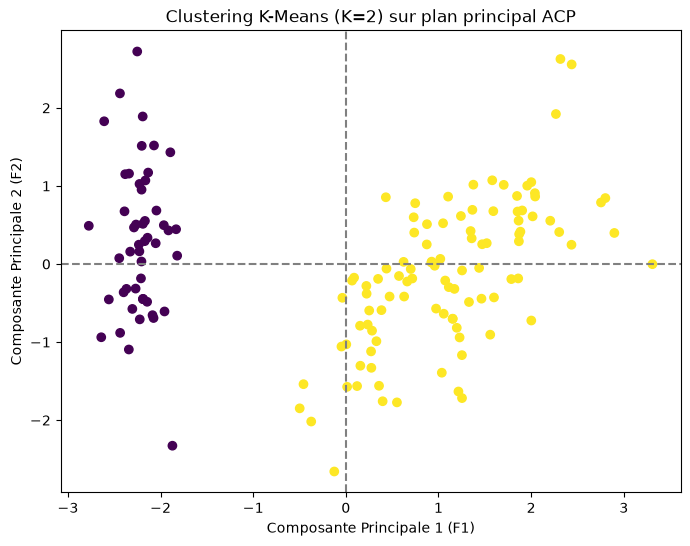

In [5]:
# 5. Diagramme de dispersion en 2D
plt.figure(figsize=(8, 6))
plt.scatter(X_acp[:, 0], X_acp[:, 1], c=clusters, cmap='viridis')
plt.title("Clustering K-Means (K=2) sur plan principal ACP")
plt.xlabel("Composante Principale 1 (F1)")
plt.ylabel("Composante Principale 2 (F2)")
plt.axhline(0, color='gray', linestyle='--')
plt.axvline(0, color='gray', linestyle='--')
plt.show()

In [6]:
# 6. Qualité des clusters (K=2)
inertie_intra = km_opt.inertia_

# Théorème de Huygens
inertie_totale = X_std.shape[1] * X_std.shape[0]
inertie_inter = inertie_totale - inertie_intra
ratio_explique = inertie_inter / inertie_totale

print("Inertie totale :", inertie_totale)
print("Inertie intra-classe :", round(inertie_intra, 1))
print("Part d'information expliquée (I_inter / I_totale) :", round(ratio_explique * 100, 1), "%")
print("Coefficient de silhouette :", round(silhouette_score(X_std, clusters), 3))

Inertie totale : 600
Inertie intra-classe : 223.7
Part d'information expliquée (I_inter / I_totale) : 62.7 %
Coefficient de silhouette : 0.58


**Évaluation de la qualité des clusters obtenus :**
* Inertie : K-Means a cherché à minimiser l'inertie intra-classe (223.7). D'après le cours, le rapport I_inter / I_totale mesure la part de l'information expliquée par la partition. Ici, nos 2 clusters expliquent 62.7 % de l'information totale.
* Coefficient de silhouette (0.58) : Ce score est bien supérieur à 0 et se rapproche de 1. Cela montre que les individus sont bien placés dans leur cluster et ne sont pas situés à la frontière entre deux groupes.

**7. Quel est l'objectif de l'apprentissage non supervisé, et en quoi diffère-t-il de l'apprentissage supervisé ?**

L'objectif de l'apprentissage non supervisé est de découvrir des structures dans les données à partir des exemples, sans disposer d'une variable cible. À l'inverse, l'apprentissage supervisé produit des règles de décision à partir d'exemples étiquetés, dans le but de prédire l'étiquette de nouvelles données.

**8. Comment choisissez-vous le nombre optimal de clusters (k) pour l'algorithme K-Means ?**

Pour choisir le nombre optimal de clusters (k) pour l'algorithme K-Means, on peut s'appuyer sur trois approches. La première approche est la méthode du coude qui consiste à tracer l'inertie intra-classe en fonction de K et à choisir le K où sa décroissance ralentit nettement. La deuxième approche est le coefficient de silhouette qui permet de choisir le K qui maximise la silhouette moyenne. Enfin, la troisième approche est le sens métier qui consiste à vérifier que les groupes obtenus peuvent être décrits et utilisés.

**9. Pouvez-vous expliquer l'idée derrière la standardisation des caractéristiques dans le contexte de l'apprentissage non supervisé ?**

Les variables sont souvent exprimées dans des unités et des ordres de grandeur très différents. Il faut donc les standardiser pour les ramener à une échelle commune, sans quoi une variable de grande amplitude dominerait les autres lors des calculs de distance, notamment pour K-means. Pour l'ACP, on utilise une ACP normalisée lorsque les unités ou les ordres de grandeur sont différents pour que toutes les variables aient le même poids.

**10. Quels sont les avantages et les limites de l'algorithme K-Means ?**

L'algorithme K-means a l'avantage de pouvoir traiter de très grands volumes de données, car la méthode se prête bien au calcul distribué selon le schéma MapReduce. En revanche, le choix de K doit être fait à l'avance et le résultat dépend des centres de départ. L'algorithme est également sensible aux valeurs aberrantes et fonctionne principalement avec des groupes compacts et à peu près sphériques. Il échoue sur des groupes allongés, emboîtés ou de densités très différentes.

**11. Comment évaluez-vous la qualité des clusters obtenus ? Quelles mesures ou critères pourriez-vous utiliser ?**

La qualité des clusters s'évalue à l'aide de l'inertie et du coefficient de silhouette. L'inertie intra-classe mesure la dispersion à l'intérieur des groupes. On cherche à la minimiser pour obtenir des groupes compacts. L'inertie inter-classe mesure l'écart entre les groupes. On cherche à la maximiser pour obtenir des groupes bien séparés. Enfin, le coefficient de silhouette indique si un individu est bien placé (proche de 1), à la frontière entre deux groupes (proche de 0) ou probablement mal affecté (négatif).